# Assignment 3

In [1]:
import numpy as np
import tqdm
import matplotlib.pyplot as plt
from numba import njit
from IPython.display import HTML, display

plt.rcParams.update({
    "font.size": 8,
    "figure.figsize": (6.2, 3.5),
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
})
# Problem 1
J = 1
KB = 1
seed = 0
# Problem 2
SWEEPS_2 = 50000
M, OMEGA, HBAR = 1.0, 1.0, 1.0
BETA = 1.0
DELTATAU = 0.1
NTAU = int(BETA/DELTATAU)

## Problem 1 *MCMC and 2D Ising Model*

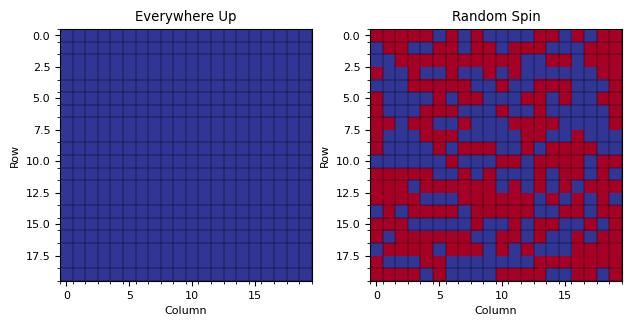

In [2]:
# Creating the grid configurations
N = 20
spins_up = np.ones((N, N), dtype=int)
spins_random = np.random.default_rng().integers(0,2,size=(20,20)) * 2 - 1

fig, (axup, axrandom) = plt.subplots(1, 2)
axup.imshow(spins_up, cmap="RdYlBu", vmin=-1, vmax=1)
axup.set_xticks(np.arange(-0.5, N, 1), minor=True)
axup.set_yticks(np.arange(-0.5, N, 1), minor=True)
axup.grid(which="minor", color="black", linewidth=0.3)
axup.set(title="Everywhere Up", xlabel="Column", ylabel="Row")
axrandom.imshow(spins_random, cmap="RdYlBu", vmin=-1, vmax=1)
axrandom.set_xticks(np.arange(-0.5, N, 1), minor=True)
axrandom.set_yticks(np.arange(-0.5, N, 1), minor=True)
axrandom.grid(which="minor", color="black", linewidth=0.3)
axrandom.set(title="Random Spin", xlabel="Column", ylabel="Row")
plt.show()

In [3]:
# Adding the Bond Energies
def total_energy(spins):
    n = spins.shape[0]
    energy = 0.0
    for i in range(n):
        for j in range(n):
            for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                neighbor = spins[(i + di) % n, (j + dj) % n]
                energy -= J * spins[i, j] * neighbor
    return energy / 2

print("Energy of Everywhere spin Up:", total_energy(spins_up))
print("Energy of Random Spins:", total_energy(spins_random))

Energy of Everywhere spin Up: -800.0
Energy of Random Spins: -28.0


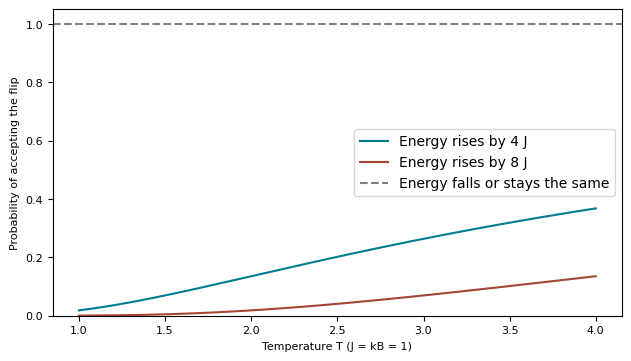

In [4]:
# Chance of accepting one proposed energy increase of a lattice held at tempurature T
temperature_axis = np.linspace(1, 4.0, 150)
fig, ax = plt.subplots()
for cost, color in [(4 * J, "#007c91"), (8 * J, "#a54632")]:
    probability = np.exp(-cost / (KB * temperature_axis))
    ax.plot(temperature_axis, probability,
            color=color, label=f"Energy rises by {cost:g} J")
ax.axhline(1, color="gray", linestyle="--", label="Energy falls or stays the same")
ax.set(xlabel="Temperature T (J = kB = 1)",
       ylabel="Probability of accepting the flip", ylim=(0, 1.05))
ax.legend(fontsize=10)
plt.show()

In [5]:
# Energy change of a single spin flip
@njit
def flip_energy(spins, i, j):
    n = spins.shape[0]
    neighbors = spins[(i - 1) % n, j] + spins[(i + 1) % n, j] + spins[i, (j - 1) % n] + spins[i, (j + 1) % n]
    return 2 * J * spins[i, j] * neighbors

In [6]:
# Defining the step function for the Metropolis Algorithm (whether or not a spin-flip is rejected or accepted)
@njit
def metropolis_step(spins, temperature, rng):
    i, j = rng.integers(0, spins.shape[0], size=2)
    delta_energy = flip_energy(spins, i, j)
    if delta_energy <= 0 or rng.random() < np.exp(-delta_energy / (KB * temperature)):
        spins[i, j] *= -1
        return 1
    return 0

In [7]:
# Run step function many times to simulate Ising Model with MCMC
@njit
def advance_ising(spins, temperature, sweeps, rng):
    n = spins.shape[0]
    magnetization = np.empty(sweeps + 1)
    magnetization[0] = spins.mean()
    accepted = 0
    for sweep in range(1, sweeps + 1):
        for _ in range(n * n):
            accepted += metropolis_step(spins, temperature, rng)
        magnetization[sweep] = spins.mean()
    return (magnetization, accepted)
# run_ising sets up lattice and rng
def run_ising(temperature, spins, sweeps, seed):
    rng = np.random.default_rng(seed)
    magnetization, accepted = advance_ising(spins, temperature, sweeps, rng)
    return (spins, magnetization, accepted / (sweeps * spins.shape[0] * spins.shape[1]))

### A: Simulate 2D Ising Model at T = 2

In [8]:
N = 24
SWEEPS = 200
SEED = seed
T = 2

final_spins_up, m_values_up, acceptance_up = run_ising(T, spins_up, SWEEPS, SEED)
final_spins_random, m_values_random, acceptance_random = run_ising(T, spins_random, SWEEPS, SEED)
print(f"Attempted flips: {SWEEPS * N * N:,}")
print(f"Acceptance rate for all spins initially up: {acceptance_up:.3f}")
print(f"Acceptance rate for random initial lattice: {acceptance_random:.3f}")

Attempted flips: 115,200
Acceptance rate for all spins initially up: 0.077
Acceptance rate for random initial lattice: 0.129


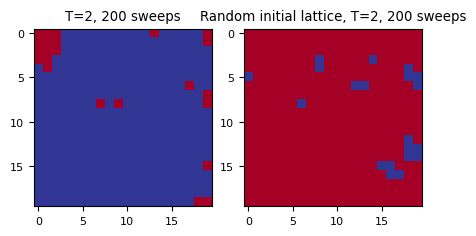

In [9]:
# Plotting the final lattices
fig, (axup, axrandom) = plt.subplots(1, 2, figsize=(4.2, 4.2))
axup.imshow(final_spins_up, cmap="RdYlBu", vmin=-1, vmax=1)
axup.set(title=f"T={T}, {SWEEPS} sweeps")
axrandom.imshow(final_spins_random, cmap="RdYlBu", vmin=-1, vmax=1)
axrandom.set(title=f"Random initial lattice, T={T}, {SWEEPS} sweeps")
plt.show()

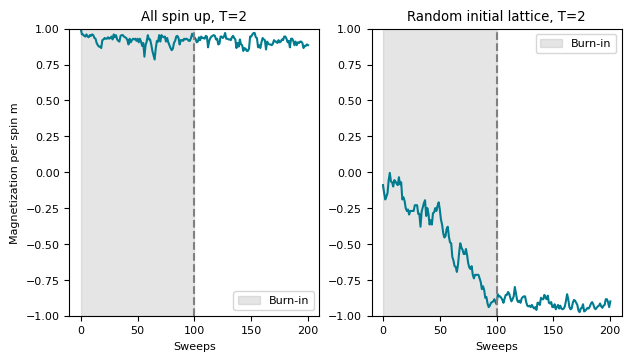

In [10]:
# Following the magnetization and setting aside burn-in time
BURNIN = 100
sweep_axis = np.arange(SWEEPS + 1)

fig, (axup, axrandom) = plt.subplots(1, 2)
axup.plot(sweep_axis, m_values_up, color="#007c91")
axup.axvspan(0, BURNIN, color="gray", alpha=0.2, label="Burn-in")
axup.axvline(BURNIN, color="gray", linestyle="--")
axup.set(xlabel="Sweeps", ylabel="Magnetization per spin m",
       title=f"All spin up, T={T}", ylim=(-1, 1))
axup.legend()
axrandom.plot(sweep_axis, m_values_random, color="#007c91")
axrandom.axvspan(0, BURNIN, color="gray", alpha=0.2, label="Burn-in")
axrandom.axvline(BURNIN, color="gray", linestyle="--")
axrandom.set(xlabel="Sweeps",
       title=f"Random initial lattice, T={T}", ylim=(-1, 1))
axrandom.legend()
plt.show()

I used a burn-in time of 100 sweeps, or 40,000 steps. As we can see in the plot above, that is about how long the random inital lattice takes to approach it's mean |m| of 1. 100 sweeps / 40K steps after the burn-in, or 200 sweeps / 80K steps total is plenty for a low standard deviation of the mean magnetization.

In [11]:
# Summarizing values of m after burn-in
samples_up = m_values_up[BURNIN + 1:]
samples_random = m_values_random[BURNIN + 1:]
print(f"Mean m for initial all spins initally up: {samples_up.mean():.3f}")
print(f"Standard deviation of m for all spins initially up: {samples_up.std():.3f}")
print(f"Mean |m| for all spins initially up: {np.abs(samples_up).mean():.3f}\n")
print(f"Mean m for initial random lattice: {samples_random.mean():.3f}")
print(f"Standard deviation of m for initial random lattice: {samples_random.std():.3f}")
print(f"Mean |m| for initial random lattice: {np.abs(samples_random).mean():.3f}")

Mean m for initial all spins initally up: 0.913
Standard deviation of m for all spins initially up: 0.030
Mean |m| for all spins initially up: 0.913

Mean m for initial random lattice: -0.911
Standard deviation of m for initial random lattice: 0.036
Mean |m| for initial random lattice: 0.911


### B: Simulating at T = 1 through T = 4

In [12]:
temperatures = np.arange(1,4.2,0.2)
runs = {}
for index, temperature in enumerate(temperatures):
    spins = np.random.default_rng().integers(0,2,size=(20,20)) * 2 - 1
    runs[temperature] = run_ising(temperature, spins, 2 * SWEEPS, SEED + index)
    _, history, rate = runs[temperature]
    mean_abs_m = np.abs(history[3 * BURNIN + 1:]).mean()
    print(f"T = {temperature:.3f}: mean |m| = {mean_abs_m:.3f}, "
          f"acceptance = {rate:.3f}")

T = 1.000: mean |m| = 1.000, acceptance = 0.009
T = 1.200: mean |m| = 0.997, acceptance = 0.013
T = 1.400: mean |m| = 0.993, acceptance = 0.018
T = 1.600: mean |m| = 0.980, acceptance = 0.027
T = 1.800: mean |m| = 0.955, acceptance = 0.054
T = 2.000: mean |m| = 0.917, acceptance = 0.136
T = 2.200: mean |m| = 0.827, acceptance = 0.155
T = 2.400: mean |m| = 0.662, acceptance = 0.254
T = 2.600: mean |m| = 0.290, acceptance = 0.346
T = 2.800: mean |m| = 0.119, acceptance = 0.419
T = 3.000: mean |m| = 0.139, acceptance = 0.458
T = 3.200: mean |m| = 0.096, acceptance = 0.497
T = 3.400: mean |m| = 0.100, acceptance = 0.530
T = 3.600: mean |m| = 0.081, acceptance = 0.562
T = 3.800: mean |m| = 0.090, acceptance = 0.587
T = 4.000: mean |m| = 0.098, acceptance = 0.608


I set the initial condition to a random lattice because it is a much more likely initial condition if you are cooling the lattice from above the critical temperature. It also gives you a good idea of burn-in time. I only used one chain per temperature, but changed the seed for each new temperature by adding the index. Some temperatures take longer to converge to their mean magnetizations, so I tripled the burn-in time to 120K steps / 300 sweeps. No reason to use thinning, we're not using Babbage's Difference Engine.

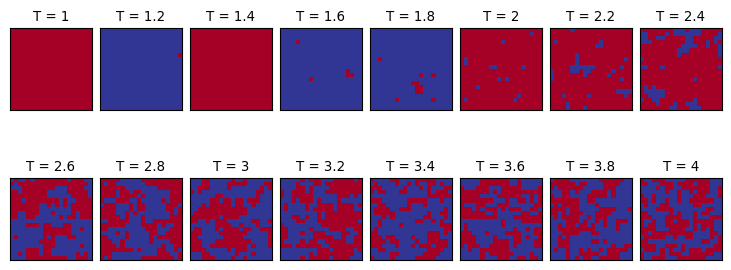

In [13]:
# Plotting final configurations at T=1 through T=4
fig, axes = plt.subplots(2, 8, figsize=(7.2, 3.0))
axes = axes.flatten()
for ax, temperature in zip(axes, temperatures):
    lattice, _, _ = runs[temperature]
    ax.imshow(lattice, cmap="RdYlBu", vmin=-1, vmax=1)
    ax.set(title=f"T = {temperature:g}", xticks=[], yticks=[])
plt.show()

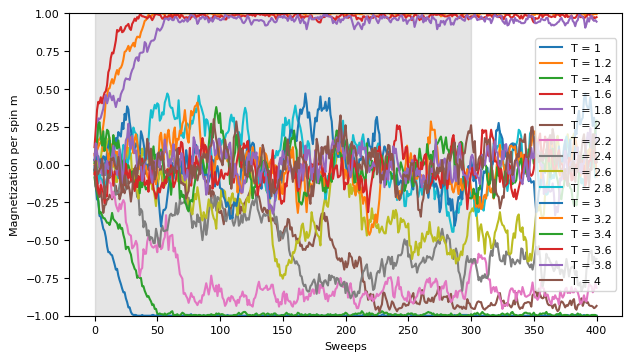

In [14]:
# Plotting the histories of the mean m for each temperature
fig, ax = plt.subplots()
double_sweep_axis = np.arange(2 * SWEEPS + 1)
for temperature in temperatures:
    _, history, _ = runs[temperature]
    ax.plot(double_sweep_axis, history, label=f"T = {temperature:g}")
ax.axvspan(0, 3 * BURNIN, color="gray", alpha=0.2)
ax.set(xlabel="Sweeps", ylabel="Magnetization per spin m",
       ylim=(-1, 1))
ax.legend()
plt.show()

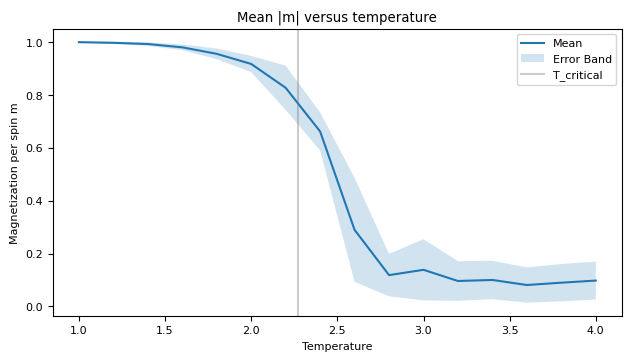

In [15]:
# Plotting the mean magnetization m versus temperature
m_of_T = np.empty(16)
m_of_T_std = np.empty(16)
for index, temperature in enumerate(temperatures):
    _, history, _ = runs[temperature]
    m_of_T[index] = np.abs(history[3 * BURNIN + 1:]).mean()
    m_of_T_std[index] = np.abs(history[3 * BURNIN + 1:]).std()
fig, ax = plt.subplots()
ax.plot(temperatures, m_of_T, label="Mean")
plt.fill_between(temperatures, m_of_T - m_of_T_std, m_of_T + m_of_T_std, alpha=0.2, label='Error Band')
ax.axvline(2.269,alpha=0.4,color="gray",label="T_critical")
ax.set(title="Mean |m| versus temperature",xlabel="Temperature", ylabel="Magnetization per spin m")
ax.legend()
plt.show()

There is a quick phase transition at T = T<sub>C</sub>, but because of how the Ising model is discretised, and the number of steps after the burn-in time, it's not super sharp.

## Problem 2 *Path Integral Monte Carlo at Finite Temperature*

In [16]:
xlow = -4
xhigh = 4
nxbins = 100
deltax = (xhigh - xlow) / nxbins
prob_histogram = np.zeros(nxbins)
x_bins = np.linspace(xlow, xhigh, nxbins + 1)
hitsize = 0.7

### A (i)

In [17]:
x_path = np.zeros(NTAU)
## analytical solution
psi_analytical = (M*OMEGA/(np.pi*HBAR))**0.25*np.exp(-M*OMEGA*x_bins**2/2/HBAR)

In [18]:
# Defining functions for simulation of the path integral
def vary_path(x_current):
    x_prime = x_current + np.random.random() * 2 * hitsize - hitsize
    return x_prime

def action(x_left, x_right):
    K = 0.5 * M * (((x_right - x_left))**2) / DELTATAU
    V = 0.5 * M * DELTATAU * (OMEGA**2) * (((x_left + x_right) / 2)**2)
    return K + V

def total_action(x_path):
    path_action = 0
    for i in range(-1, NTAU-1):
        path_action += action(x_path[i], x_path[i+1])
    return path_action

def delta_action(x_path, x_prime, i):
    x_left = x_path[i-1]
    x_right = x_path[i+1] if i < NTAU-1 else x_path[0] #PBC.
    daction = action(x_left, x_prime) + action(x_prime, x_right) 
    daction -= action(x_left, x_path[i]) + action(x_path[i], x_right) #compute the resulting change from u in delta S.
    return daction

def MCMC(x_path, prob_histogram, burn_in, sweep):
    steps = 0
    acceptance = 0
    for i in range(NTAU):
        x_prime = vary_path(x_path[i])
        daction = delta_action(x_path, x_prime, i)
        steps += 1
        if daction <= 0:            
            x_path[i] = x_prime
            acceptance += 1
        else:        
            prob = np.exp(-daction)
            if np.random.random() < prob:
                x_path[i] = x_prime
                acceptance += 1
    hist, _ = np.histogram(x_path, bins=x_bins)
    if sweep > burn_in:
        prob_histogram += hist
    return (acceptance / steps)

In [19]:
# Simulating the path integral
burn_in = 5000
sweeps = 0
accepted = 0
x2_series = np.empty(SWEEPS_2)
for k in tqdm.tqdm(range(SWEEPS_2)):
    sweeps += 1
    accepted += MCMC(x_path, prob_histogram, burn_in, k)
    x2_series[k] = np.mean(x_path**2)
acceptance = accepted / sweeps
x2_single = x2_series.mean()
x2_err_naive = x2_series.std() / np.sqrt(SWEEPS_2)
print("Acceptance Rate:",acceptance)

100%|██████████| 50000/50000 [00:04<00:00, 10856.65it/s]

Acceptance Rate: 0.477514000000006


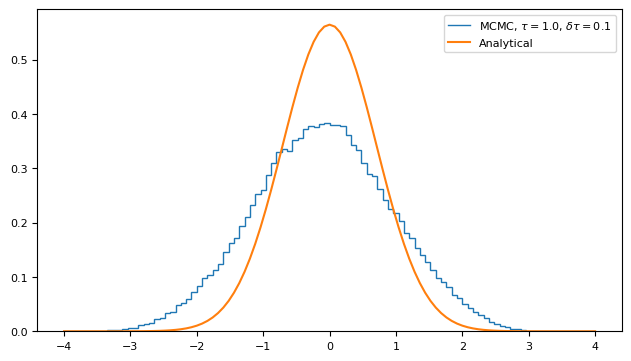

In [20]:
plt.figure()
plt.stairs(prob_histogram/np.sum(prob_histogram*deltax), x_bins, label=f"MCMC, $\\tau = {BETA}$, $\\delta\\tau={DELTATAU}$")
plt.plot(x_bins, psi_analytical*psi_analytical.conjugate(), label="Analytical")
plt.legend()
plt.show()

I arbitrarily used a burn-in of 5000 because the burn-in only affected the results noticeably once you threw away so many sweeps your data became less reliable.

Autocorrelation:

In [21]:
@njit
def variance(values):
    centered = values - values.mean()
    return (centered**2).mean()

@njit
def covariance(values, lag):
    centered = values - values.mean()
    total = 0.0
    for t in range(len(values) - lag):
        total += centered[t] * centered[t + lag]
    return total / len(values)

@njit
def autocorrelation(values, max_lag):
    variance_of_x = variance(values)
    rho = np.empty(max_lag + 1)
    for lag in range(max_lag + 1):
        rho[lag] = covariance(values, lag) / variance_of_x
    return rho

def exact_autocorrelation(r, lags):
    return r**lags

In [22]:
# Find r-values
x_centered = np.asarray(x2_series) - np.mean(x2_series)
r = np.sum(x_centered[:-1] * x_centered[1:]) / np.sum(x_centered**2)

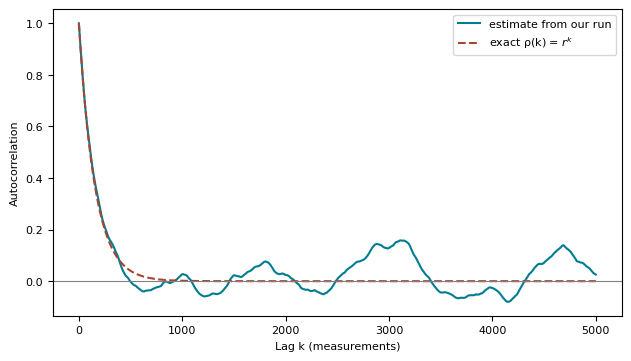

In [23]:
# Plot autocorrelation
max_lag = 5000
lags = np.arange(max_lag+1)
autocorr_estimate = autocorrelation(x2_series, max_lag)
fig, ax = plt.subplots()
ax.plot(lags, autocorr_estimate, color="#007c91", label="estimate from our run")
ax.plot(lags, exact_autocorrelation(r, lags), "--", color="#a54632", label="exact ρ(k) = $r^k$")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Lag k (measurements)", ylabel="Autocorrelation")
ax.legend()
plt.show()

In [24]:
# Functions for finding the blocking error
def split_into_blocks(values, block_length):
    n_blocks = len(values) // block_length
    return values[:n_blocks * block_length].reshape(n_blocks, block_length)

def block_means(values, block_length):
    return split_into_blocks(values, block_length).mean(axis=1)

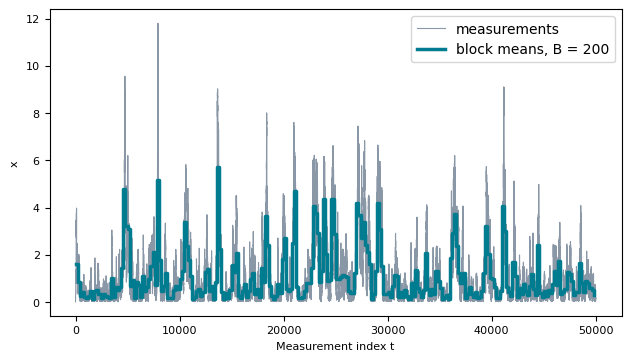

In [25]:
tau_int = (1+r) / (2*(1-r))
# Finding and plotting the blocking error
block_length = 200
segment = x2_series
means = block_means(segment, block_length)
x2_err_single = means.std(ddof=1) / np.sqrt(len(means))
fig, ax = plt.subplots()
ax.plot(segment, color="#8a97a6", linewidth=0.8, label="measurements")
ax.step(np.arange(0, 50000, block_length), means, where="post", color="#007c91",
        linewidth=2.5, label=f"block means, B = {block_length}")
ax.set(xlabel="Measurement index t", ylabel="x")
ax.legend(fontsize=10)
plt.show()

### A (ii)

As $\delta\tau$ decreases, N increases because $N=\beta/\delta\tau$. Since $\bar{x}=\frac{1}{N}\sum_{i}^{N}{x_i}$, each change in x_i affects xbar less, which means it takes more steps and sweeps for xbar to move away, or decorrelate, from its previous positions.

### B (i)

In [26]:
h_shift = 0.7
x_path = np.zeros(NTAU)

In [ ]:
def MCMC_both(x_path, prob_histogram, burn_in, sweep):
    steps = 0
    acceptance = 0
    for i in range(NTAU):
        x_prime = vary_path(x_path[i])
        daction = delta_action(x_path, x_prime, i)
        steps += 1
        if daction <= 0:            
            x_path[i] = x_prime
            acceptance += 1
        else:        
            prob = np.exp(-daction)
            if np.random.random() < prob:
                x_path[i] = x_prime
                acceptance += 1
    hist, _ = np.histogram(x_path, bins=x_bins)
    d = np.random.uniform(-h_prime, h_prime)
    x_path += d
    if sweep > burn_in:
        prob_histogram += hist
    return (acceptance / steps)

In [27]:
import json
results = {
"tsn": "200075102",
"seed": seed,
"m": [float(v) for v in m_of_T],
"h": hitsize, "acceptance": float(acceptance), "n_sweeps_single": SWEEPS_2,
"x2_single": float(x2_single), "x2_err_single": float(x2_err_single),
"x2_err_naive": float(x2_err_naive), "tau_single": float(tau_int),
# Problem 2B (bonus); leave out the fields of any part you skip
"h_shift": h_shift, "n_sweeps_both": SWEEPS_2,
# "x2_both": float(x2_both), "x2_err_both": float(x2_err_both),
# "tau_both": float(tau_both),
# "n_sweeps_beta": n_beta,
# "x2_beta": [float(v) for v in x2_beta],
# "x2_err_beta": [float(v) for v in x2_err_beta],
}
with open("results.json", "w") as f:
    json.dump(results, f)

# AI Use Summary
I mostly used Google Gemini
* How to create an np array with random +1 and -1 values
* Explaining what thinning is.
* Stylizing the plot of mean magnetization versus temperature
    * *Prompt: "how to make errorbars a region above and below the line rather than just a vertical bar through each point matplotlib"*
* Explain autocorrelation and what error from blocking is.
* What is 2A(ii) asking for?